In [1]:
import numpy as np
from scipy.spatial.transform import Rotation

def estimate_similarity_transform(src_points, dst_points):
    """
    Estimate 2D similarity transform parameters s, R, t from src_points to dst_points.
    q = s * R * p + t

    Parameters:
        src_points: numpy array, shape (N, 2), source point set
        dst_points: numpy array, shape (N, 2), target point set
    Returns:
        s: float, scaling factor
        R: numpy array, shape (2, 2), rotation matrix
        t: numpy array, shape (2,), translation vector
    """
    # 0. Input validation
    src = np.asarray(src_points, dtype=np.float64)
    dst = np.asarray(dst_points, dtype=np.float64)
    if src.shape != dst.shape or src.shape[1] != 2:
        raise ValueError("Input point sets must have the same shape (N, 2)")

    N = src.shape[0]
    if N < 2:
        raise ValueError("At least 2 point pairs are required to estimate a similarity transform")

    # 1. Compute centroids
    mean_src = np.mean(src, axis=0)
    mean_dst = np.mean(dst, axis=0)

    # 2. Center the point sets
    src_centered = src - mean_src
    dst_centered = dst - mean_dst

    # 3. Compute variance of the source point set (denominator)
    var_src = np.sum(src_centered ** 2)
    if var_src < 1e-12:
        raise ValueError("Source point set is degenerate (all points coincide), cannot estimate transform")

    # 4. Compute cross-covariance matrix H (2x2)
    H = src_centered.T @ dst_centered

    # 5. SVD decomposition
    U, S, Vt = np.linalg.svd(H)

    # 6. Compute rotation matrix R
    R = Vt.T @ U.T

    # Prevent reflection (ensure det(R) = 1)
    if np.linalg.det(R) < 0:
        Vt[-1, :] *= -1
        R = Vt.T @ U.T

    # 7. Compute scaling factor s
    s = np.sum(S) / var_src

    # 8. Compute translation vector t
    t = mean_dst - s * (R @ mean_src)

    return s, R, t

In [2]:
src_points = [[ 9268.10498705,  5372.12573632],
        [11608.60652386,  7991.54335424],
        [ 2104.62351716,  9054.56798044],
        [11387.82208142,  2591.78439192],
        [ 3140.44715464,  7181.5287383 ],
        [12376.88498148, 12071.8537054 ],
        [ 7138.52878504,  8589.65744487]]
dst_points = [[632.05359815, 363.82857238],
        [807.1638318 , 527.89470658],
        [166.30902478, 634.57862699],
        [772.76566694, 165.17135792],
        [220.27918955, 500.65704647],
        [867.80435004, 802.82453498],
        [521.23108007, 581.43136972]]

s,R,t =estimate_similarity_transform(src_points, dst_points)

x = [s*R[0,0],s*R[0,1],t[0],s*R[1,0],s*R[1,1],t[1]]

In [3]:
import scanpy as sc
adata_HD = sc.read("./h5ad/adata_HD.h5ad")
subset = adata_HD[adata_HD.obs["batch"] == "nS06"]
spots = subset.obsm['spatial']
spot_types = subset.obs['type']

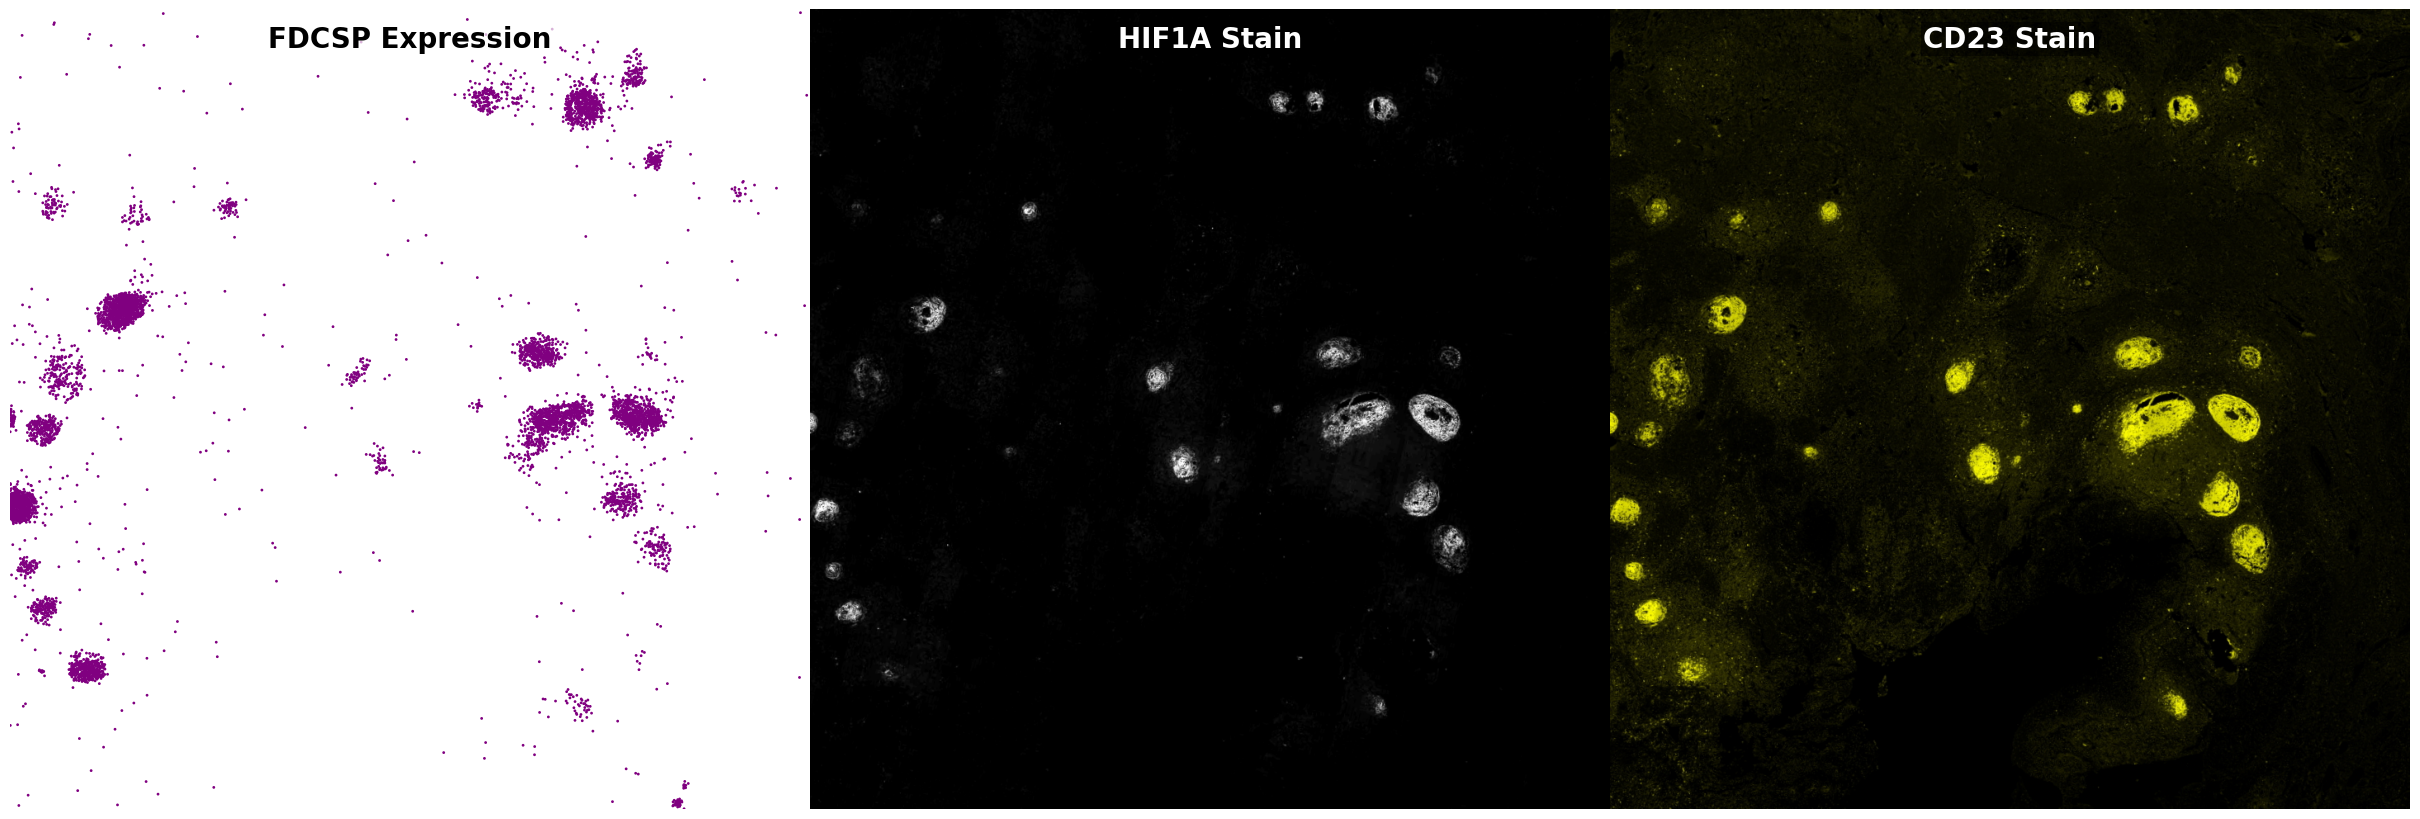

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import cv2
from PIL import Image

# --- Helper functions ---
def get_rect(pts):
    pts = pts.astype(np.float32)
    box = cv2.boxPoints(cv2.minAreaRect(pts))
    y_s = box[np.argsort(box[:, 1])]
    t, b = y_s[:2][np.argsort(y_s[:2, 0])], y_s[2:][np.argsort(y_s[2:, 0])]
    return np.array([t[0], t[1], b[1], b[0]], dtype=np.float32)

def crop_rot(path, rect):
    img = cv2.imread(path)
    if img is None: raise FileNotFoundError(f"Image not found: {path}")
    w = int(max(np.linalg.norm(rect[0]-rect[1]), np.linalg.norm(rect[3]-rect[2])))
    h = int(max(np.linalg.norm(rect[0]-rect[3]), np.linalg.norm(rect[1]-rect[2])))
    dst = np.array([[0,0], [w,0], [w,h], [0,h]], dtype=np.float32)
    M = cv2.getPerspectiveTransform(rect, dst)
    return cv2.cvtColor(cv2.warpPerspective(img, M, (w, h)), cv2.COLOR_BGR2RGB)

# --- 1. Data preparation and processing ---
rL = get_rect(spots)
org, ux, uy = rL[3], (rL[2]-rL[3]), (rL[0]-rL[3])
M_mat = np.vstack([ux/np.linalg.norm(ux), uy/np.linalg.norm(uy)])
pts_L = (spots - org) @ M_mat.T

x_min, x_max = pts_L[:, 0].min(), pts_L[:, 0].max()
y_min, y_max = pts_L[:, 1].min(), pts_L[:, 1].max()

rR = get_rect(spots@ [[x[0],x[3]],[x[1],x[4]]]+np.array([x[2], x[5]]))
img_CD23 = crop_rot('./fluorescence/CD23_nS06.jpg', rR)
img_HIF1A = crop_rot('./fluorescence/HIF1A_nS06.jpg', rR) # Note: check the file suffix

gene_col = subset[:, 'FDCSP'].X
if hasattr(gene_col, 'toarray'):
    fdcsp_vals = gene_col.toarray().flatten()
else:
    fdcsp_vals = np.asarray(gene_col).flatten()
fdcsp_mask = fdcsp_vals.astype(float)>0

# --- 2. Plotting setup ---
# Adjust figsize according to the image aspect ratio; keep a wide strip here
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(24, 8)) 

# Set subplot spacing to 0 for seamless stitching
plt.subplots_adjust(wspace=0, hspace=0)

# Set background colors
ax1.set_facecolor("white")
ax2.set_facecolor('black')
ax3.set_facecolor('black')

# --- Left panel: FDCSP (white background) ---
ax1.scatter(pts_L[fdcsp_mask][:, 0], pts_L[fdcsp_mask][:, 1], 
            c="purple", s=4, alpha=1.0, edgecolors='none')
ax1.set_xlim(x_min, x_max)
ax1.set_ylim(y_min, y_max)
ax1.axis('off')

# Use text instead of title, fixed at the top inside the panel
# transform=ax1.transAxes uses relative coordinates (0~1)
# bbox adds a background box to keep the text readable
ax1.text(0.5, 0.98, "FDCSP Expression", 
         transform=ax1.transAxes,
         ha='center', va='top',
         fontsize=20, color='black', fontweight='bold',
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2.0))

# --- Middle panel: HIF1A (black background) ---
ax2.imshow(img_HIF1A, extent=[x_min, x_max, y_min, y_max], aspect='auto')
ax2.set_xlim(x_min, x_max)
ax2.set_ylim(y_min, y_max)
ax2.axis('off')

# White text on black background, with semi-transparent black background box
ax2.text(0.5, 0.98, "HIF1A Stain", 
         transform=ax2.transAxes,
         ha='center', va='top',
         fontsize=20, color='white', fontweight='bold',
         bbox=dict(facecolor='black', alpha=0.5, edgecolor='none', pad=2.0))

# --- Right panel: CD23 (black background) ---
ax3.imshow(img_CD23, extent=[x_min, x_max, y_min, y_max], aspect='auto')
ax3.set_xlim(x_min, x_max)
ax3.set_ylim(y_min, y_max)
ax3.axis('off')

ax3.text(0.5, 0.98, "CD23 Stain", 
         transform=ax3.transAxes,
         ha='center', va='top',
         fontsize=20, color='white', fontweight='bold',
         bbox=dict(facecolor='black', alpha=0.5, edgecolor='none', pad=2.0))

# pad=0 removes extra whitespace around the edges
plt.tight_layout(pad=0)
plt.show()